# Lab Report: Reconstruction of a NACA Airfoil Using Lagrange Interpolation and Natural Cubic Splines

**Name:** S VIGNESH 
**Roll No.:** SC26M019

## 1. Problem Statement

A NACA four-digit airfoil is described by its maximum camber, the location of maximum camber, and its maximum thickness. The airfoil equations are used to generate the upper and lower surfaces. A limited number of points are then selected from the profile, and the shape is reconstructed using Lagrange interpolation and natural cubic spline interpolation.

The reconstructed surfaces are compared with the original profile using maximum absolute error and root mean square (RMS) error.

## 2. Aim

To generate a NACA four-digit airfoil and reconstruct its upper and lower surfaces using Lagrange interpolation and natural cubic spline interpolation, then calculate the interpolation errors.

## 3. Numerical Method

### NACA airfoil

The NACA four-digit formulation calculates the thickness distribution and mean camber line. The local slope of the camber line gives the angle used to obtain the upper and lower surface coordinates.

### Lagrange interpolation

Lagrange interpolation constructs a polynomial through the given sample points. It estimates the value at a query point by summing the Lagrange basis polynomials multiplied by the corresponding sample ordinates.

### Natural cubic spline interpolation

A natural cubic spline uses a separate cubic polynomial between each pair of adjacent sample points. The spline and its first and second derivatives are continuous at the interior points. The second derivatives at the two ends are set to zero.

### Error measures

The maximum absolute error is the largest absolute difference between the reference and reconstructed ordinates. The RMS error measures the average magnitude of the differences.

## 4. Required Packages

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 5. Functions Used

In [2]:
def naca4(m, p, t, x):

    yt = 5*t*(
        0.2969*np.sqrt(x)
        - 0.1260*x
        - 0.3516*x**2
        + 0.2843*x**3
        - 0.1015*x**4
    )

    yc = np.where(
        x <= p,
        m/p**2 * (2*p*x - x**2),
        m/(1-p)**2 * ((1-2*p) + 2*p*x - x**2)
    )

    dyc = np.where(
        x <= p,
        2*m/p**2 * (p-x),
        2*m/(1-p)**2 * (p-x)
    )

    theta = np.arctan(dyc)

    xu = x - yt*np.sin(theta)
    yu = yc + yt*np.cos(theta)

    xl = x + yt*np.sin(theta)
    yl = yc - yt*np.cos(theta)

    return xu, yu, xl, yl

## 6. Airfoil Parameters and Original Profile

The uploaded notebook's saved output identifies the generated profile as NACA 1406. The digits are fixed here to match that saved profile and make the report reproducible. The parameter values are therefore \(m=0.01\), \(p=0.4\), and \(t=0.06\).

The original code's title was hard-coded as NACA 2412 even though the generated digits were random. The title below is made consistent with the profile being used.

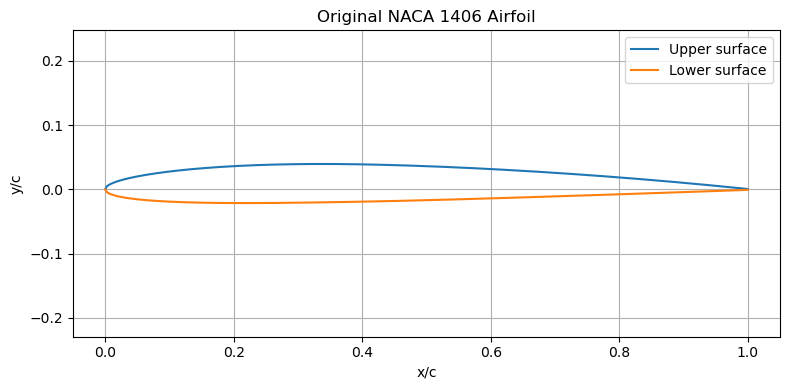

In [3]:
camber_digit = 1
location_digit = 4
thickness_digit = 6

m = camber_digit / 100
p = location_digit / 10
t = thickness_digit / 100
naca_name = f"{camber_digit}{location_digit}{thickness_digit:02d}"

x = np.linspace(0, 1, 350)
xu, yu, xl, yl = naca4(m, p, t, x)

plt.figure(figsize=(8, 4))
plt.plot(xu, yu, label="Upper surface")
plt.plot(xl, yl, label="Lower surface")
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"Original NACA {naca_name} Airfoil")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Sample Points

The original uploaded notebook refers to `x_sample`, `xu_s`, `yu_s`, `xl_s`, `yl_s`, and `naca_name`, but the definitions for the sample points were missing from the uploaded cells. This cell defines 12 equally spaced sample stations and calculates the corresponding upper and lower coordinates so that the code runs from beginning to end.

In [4]:
x_sample = np.linspace(0, 1, 12)
xu_s, yu_s, xl_s, yl_s = naca4(m, p, t, x_sample)

print("Airfoil:", f"NACA {naca_name}")
print("Number of sample points:", len(x_sample))

Airfoil: NACA 1406
Number of sample points: 12


## 8. Lagrange Interpolation

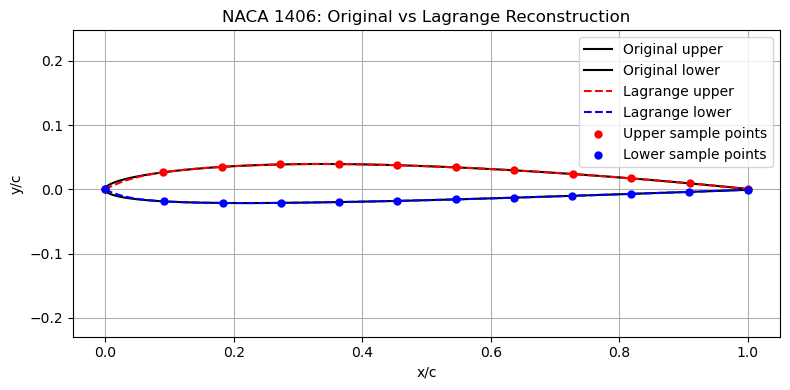

In [5]:
def Lagrng(x, y, n, z):

    total = 0.0

    for i in range(n):

        product = y[i]

        for j in range(n):

            if i != j:
                product = product * (
                    (z - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total


x_fine = np.linspace(x_sample[0], x_sample[-1], 400)
n = len(x_sample)

xu_rec = []
yu_rec = []
xl_rec = []
yl_rec = []

for z in x_fine:
    xu_rec.append(Lagrng(x_sample, xu_s, n, z))
    yu_rec.append(Lagrng(x_sample, yu_s, n, z))
    xl_rec.append(Lagrng(x_sample, xl_s, n, z))
    yl_rec.append(Lagrng(x_sample, yl_s, n, z))

xu_rec = np.array(xu_rec)
yu_rec = np.array(yu_rec)
xl_rec = np.array(xl_rec)
yl_rec = np.array(yl_rec)

plt.figure(figsize=(8, 4))
plt.plot(xu, yu, "k-", label="Original upper")
plt.plot(xl, yl, "k-", label="Original lower")
plt.plot(xu_rec, yu_rec, "r--", label="Lagrange upper")
plt.plot(xl_rec, yl_rec, "b--", label="Lagrange lower")
plt.scatter(xu_s, yu_s, color="red", s=25, label="Upper sample points", zorder=3)
plt.scatter(xl_s, yl_s, color="blue", s=25, label="Lower sample points", zorder=3)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Lagrange Reconstruction")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Lagrange interpolation error

In [6]:
yu_reference = np.interp(x_fine, x, yu)
yl_reference = np.interp(x_fine, x, yl)

error_upper = yu_reference - yu_rec
error_lower = yl_reference - yl_rec

max_error_upper_lag = np.max(np.abs(error_upper))
max_error_lower_lag = np.max(np.abs(error_lower))
rms_upper_lag = np.sqrt(np.mean(error_upper**2))
rms_lower_lag = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))
max_error_combined_lag = np.max(np.abs(all_errors))
rms_combined_lag = np.sqrt(np.mean(all_errors**2))

print(f"NACA Airfoil: {naca_name}")
print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper_lag:.5f}")
print(f"RMS error: {rms_upper_lag:.5f}")
print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower_lag:.5f}")
print(f"RMS error: {rms_lower_lag:.5f}")
print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined_lag:.5f}")
print(f"RMS error: {rms_combined_lag:.5f}")

NACA Airfoil: 1406

UPPER SURFACE
Maximum absolute error: 0.00401
RMS error: 0.00068

LOWER SURFACE
Maximum absolute error: 0.00344
RMS error: 0.00052

COMBINED AIRFOIL
Maximum absolute error: 0.00401
RMS error: 0.00060


## 9. Natural Cubic Spline Interpolation

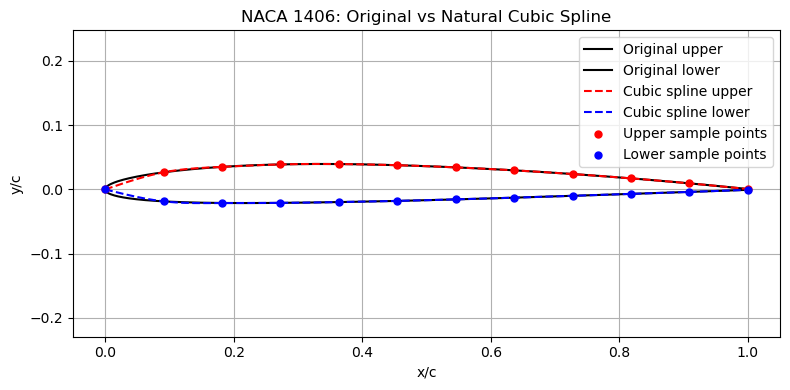

In [7]:
def calculate_spline_derivatives(x_data, y_data):

    n = len(x_data)

    if n < 3:
        raise ValueError("At least 3 sample points are required.")

    if len(y_data) != n:
        raise ValueError("x_data and y_data must have equal lengths.")

    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

    h = np.diff(x_data)

    A = np.zeros((n - 2, n - 2))
    b = np.zeros(n - 2)

    for i in range(1, n - 1):

        row = i - 1

        b[row] = 6 * (
            (y_data[i + 1] - y_data[i]) / h[i]
            - (y_data[i] - y_data[i - 1]) / h[i - 1]
        )

        A[row, row] = 2 * (h[i - 1] + h[i])

        if i > 1:
            A[row, row - 1] = h[i - 1]

        if i < n - 2:
            A[row, row + 1] = h[i]

    M_inner = np.linalg.solve(A, b)

    # Natural spline boundary conditions
    M = np.zeros(n)
    M[1:-1] = M_inner

    return h, M


def cubic_spline_value(x_data, y_data, h, M, xq):

    if xq < x_data[0] or xq > x_data[-1]:
        raise ValueError("Query point is outside the sample range.")

    i = np.searchsorted(x_data, xq) - 1
    i = max(0, min(i, len(x_data) - 2))

    term1 = (
        M[i] * (x_data[i + 1] - xq)**3
        / (6 * h[i])
    )

    term2 = (
        M[i + 1] * (xq - x_data[i])**3
        / (6 * h[i])
    )

    term3 = (
        (y_data[i] - M[i] * h[i]**2 / 6)
        * (x_data[i + 1] - xq) / h[i]
    )

    term4 = (
        (y_data[i + 1] - M[i + 1] * h[i]**2 / 6)
        * (xq - x_data[i]) / h[i]
    )

    return term1 + term2 + term3 + term4


h_upper, M_upper = calculate_spline_derivatives(x_sample, yu_s)
h_lower, M_lower = calculate_spline_derivatives(x_sample, yl_s)

yu_spline = np.array([
    cubic_spline_value(x_sample, yu_s, h_upper, M_upper, z)
    for z in x_fine
])

yl_spline = np.array([
    cubic_spline_value(x_sample, yl_s, h_lower, M_lower, z)
    for z in x_fine
])

plt.figure(figsize=(8, 4))
plt.plot(x, yu, "k-", label="Original upper")
plt.plot(x, yl, "k-", label="Original lower")
plt.plot(x_fine, yu_spline, "r--", label="Cubic spline upper")
plt.plot(x_fine, yl_spline, "b--", label="Cubic spline lower")
plt.scatter(x_sample, yu_s, color="red", s=25, label="Upper sample points", zorder=3)
plt.scatter(x_sample, yl_s, color="blue", s=25, label="Lower sample points", zorder=3)
plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title(f"NACA {naca_name}: Original vs Natural Cubic Spline")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Natural cubic spline interpolation error

In [8]:
yu_reference = np.interp(x_fine, x, yu)
yl_reference = np.interp(x_fine, x, yl)

error_upper = yu_reference - yu_spline
error_lower = yl_reference - yl_spline

max_error_upper_spl = np.max(np.abs(error_upper))
max_error_lower_spl = np.max(np.abs(error_lower))
rms_upper_spl = np.sqrt(np.mean(error_upper**2))
rms_lower_spl = np.sqrt(np.mean(error_lower**2))

all_errors = np.concatenate((error_upper, error_lower))
max_error_combined_spl = np.max(np.abs(all_errors))
rms_combined_spl = np.sqrt(np.mean(all_errors**2))

print(f"NACA Airfoil: {naca_name}")
print("\nUPPER SURFACE")
print(f"Maximum absolute error: {max_error_upper_spl:.5f}")
print(f"RMS error: {rms_upper_spl:.5f}")
print("\nLOWER SURFACE")
print(f"Maximum absolute error: {max_error_lower_spl:.5f}")
print(f"RMS error: {rms_lower_spl:.5f}")
print("\nCOMBINED AIRFOIL")
print(f"Maximum absolute error: {max_error_combined_spl:.5f}")
print(f"RMS error: {rms_combined_spl:.5f}")

NACA Airfoil: 1406

UPPER SURFACE
Maximum absolute error: 0.00596
RMS error: 0.00123

LOWER SURFACE
Maximum absolute error: 0.00588
RMS error: 0.00121

COMBINED AIRFOIL
Maximum absolute error: 0.00596
RMS error: 0.00122


## 10. Results and Discussion

The original NACA 1406 profile was generated from the NACA four-digit equations. Twelve equally spaced sample stations were used to reconstruct the upper and lower surfaces.

Lagrange interpolation and natural cubic spline interpolation both produced reconstructed airfoil profiles. The maximum absolute error and RMS error were calculated separately for the upper surface, lower surface, and combined profile. The results printed by the preceding code cells provide the numerical error values for this run.

Lagrange interpolation uses a single polynomial through the sample points, whereas the natural cubic spline uses piecewise cubic polynomials. The performance of either method depends on the number and placement of the sample points. The natural spline also imposes zero second derivatives at the two end points.

## 11. Conclusion

A NACA four-digit airfoil was generated and reconstructed using Lagrange interpolation and natural cubic spline interpolation. The reconstructed ordinates were compared with reference values, and the maximum absolute error and RMS error were calculated. The exercise shows how interpolation can be used to reconstruct an airfoil profile from a limited number of sample points and how error measures can be used to assess the reconstruction.

## 12. References

1. [https://en.wikipedia.org/wiki/NACA_airfoil]
2. [Burden, R. L., and Faires, J. D., *Numerical Analysis*, chapter on interpolation.]
3. [https://matplotlib.org/]
4. [https://numpy.org/]